# Flood Probability Prediction Case Study

This case study builds a regression model to estimate flood probability from environmental, infrastructure, climate, and human-impact indicators. The workflow covers data loading, exploratory analysis, data cleaning, model training, evaluation, persistence, and a sample prediction.

In [1]:
import pandas as pd

df= pd.read_csv('/content/train.csv.zip')

## 1. Load the Dataset

The training data is read into a pandas DataFrame. Each row represents one observation, the predictor columns describe flood-related conditions, and `FloodProbability` is the continuous target that the model will learn to predict.

In [2]:
df

,id,MonsoonIntensity,TopographyDrainage,RiverManagement,Deforestation,Urbanization,ClimateChange,DamsQuality,Siltation,AgriculturalPractices,...,DrainageSystems,CoastalVulnerability,Landslides,Watersheds,DeterioratingInfrastructure,PopulationScore,WetlandLoss,InadequatePlanning,PoliticalFactors,FloodProbability
0,0,5,8,5,8,6,4,4,3,3,...,5,3,3,5,4,7,5,7,3,0.445
1,1,6,7,4,4,8,8,3,5,4,...,7,2,0,3,5,3,3,4,3,0.450
2,2,6,5,6,7,3,7,1,5,4,...,7,3,7,5,6,8,2,3,3,0.530
3,3,3,4,6,5,4,8,4,7,6,...,2,4,7,4,4,6,5,7,5,0.535
4,4,5,3,2,6,4,4,3,3,3,...,2,2,6,6,4,1,2,3,5,0.415
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1117952,1117952,3,3,4,10,4,5,5,7,10,...,7,8,7,2,2,1,4,6,4,0.495
1117953,1117953,2,2,4,3,9,5,8,1,3,...,9,4,4,3,7,4,9,4,5,0.480
1117954,1117954,7,3,9,4,6,5,9,1,3,...,5,5,5,5,6,5,5,2,4,0.485
1117955,1117955,7,3,3,7,5,2,3,4,6,...,6,8,5,3,4,6,7,6,4,0.495


## 2. Inspect the Dataset

Displaying the DataFrame gives an initial view of the number of observations, feature names, value ranges, and the target column. This is the first check that the file was loaded correctly.

In [3]:
df.isnull().sum()

,0
id,0
MonsoonIntensity,0
TopographyDrainage,0
RiverManagement,0
Deforestation,0
Urbanization,0
ClimateChange,0
DamsQuality,0
Siltation,0
AgriculturalPractices,0


## 3. Check Missing Values

Missing-value analysis is necessary before training. Most scikit-learn estimators cannot train directly on null values, so this check confirms whether imputation or row removal is required.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1117957 entries, 0 to 1117956
Data columns (total 22 columns):
 #   Column                           Non-Null Count    Dtype  
---  ------                           --------------    -----  
 0   id                               1117957 non-null  int64  
 1   MonsoonIntensity                 1117957 non-null  int64  
 2   TopographyDrainage               1117957 non-null  int64  
 3   RiverManagement                  1117957 non-null  int64  
 4   Deforestation                    1117957 non-null  int64  
 5   Urbanization                     1117957 non-null  int64  
 6   ClimateChange                    1117957 non-null  int64  
 7   DamsQuality                      1117957 non-null  int64  
 8   Siltation                        1117957 non-null  int64  
 9   AgriculturalPractices            1117957 non-null  int64  
 10  Encroachments                    1117957 non-null  int64  
 11  IneffectiveDisasterPreparedness  1117957 non-null 

## 4. Review Data Types and Memory Usage

`df.info()` summarizes the schema, non-null counts, data types, and approximate memory usage. Confirming that the predictors are numeric is important because the regression model expects numerical inputs.

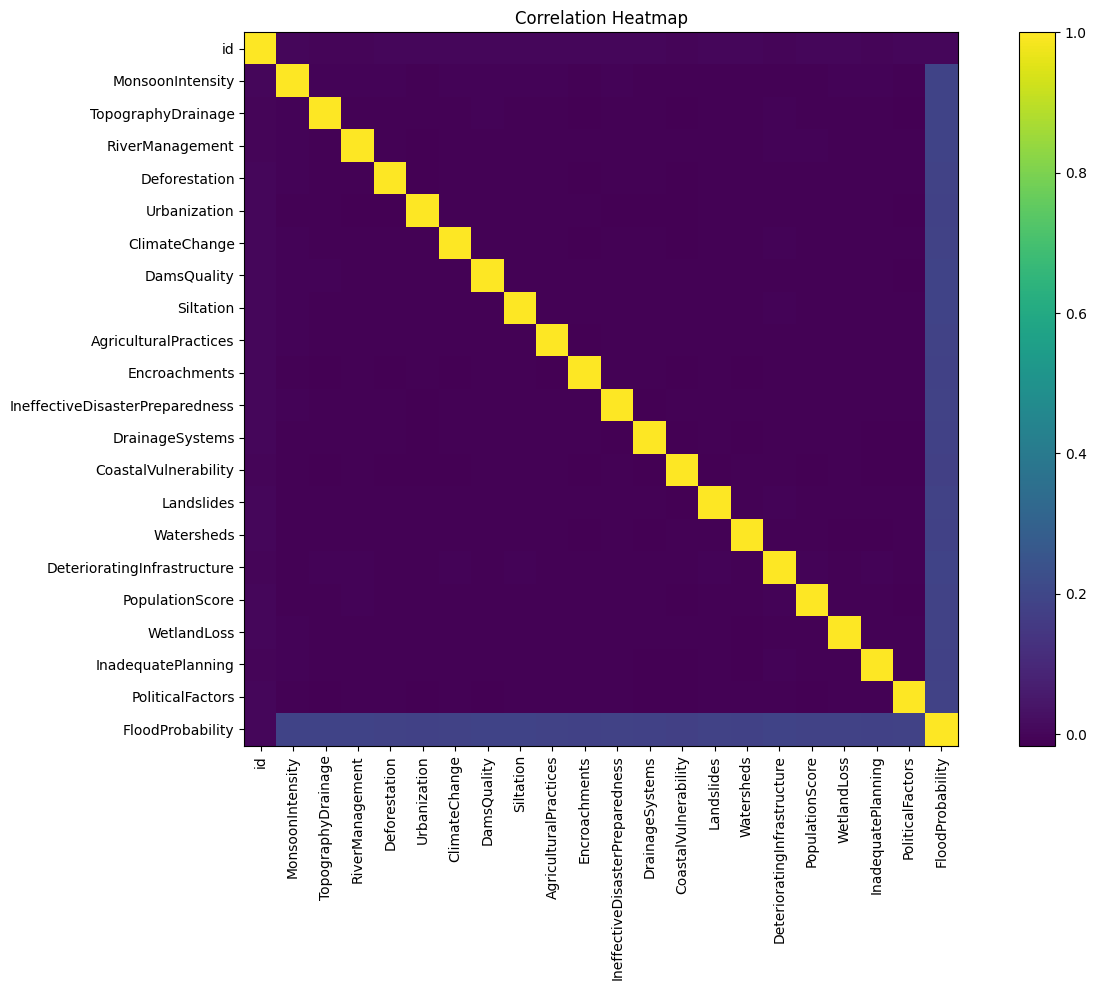

In [5]:
import matplotlib.pyplot as plt

corr = df.select_dtypes(include=['int64','float64']).corr()

plt.figure(figsize=(14,10))
plt.imshow(corr)
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## 5. Correlation Analysis

The correlation heatmap compares numerical variables with one another and with `FloodProbability`. Strong relationships can reveal useful predictors, possible redundancy between features, and directions for future feature engineering.

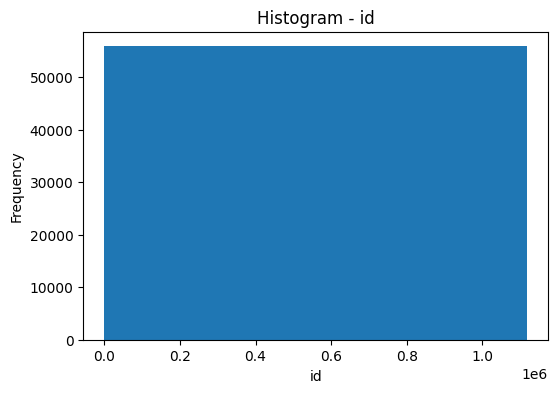

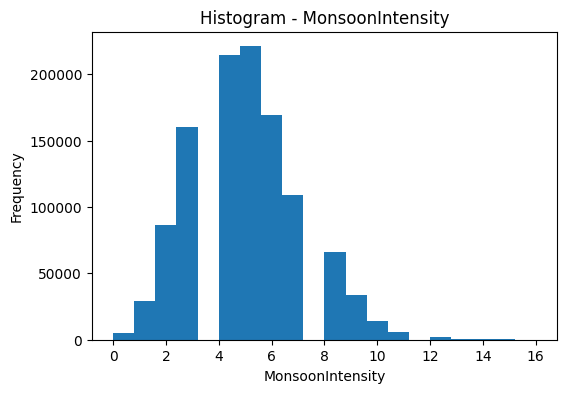

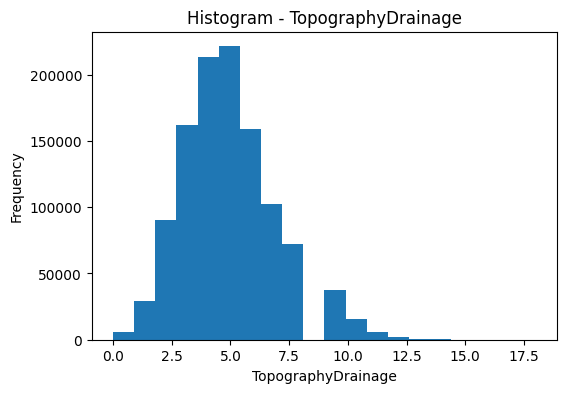

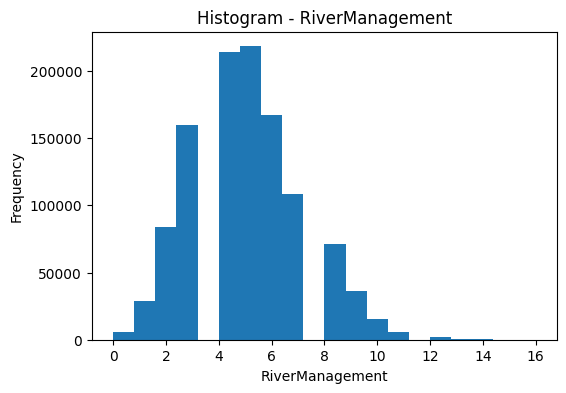

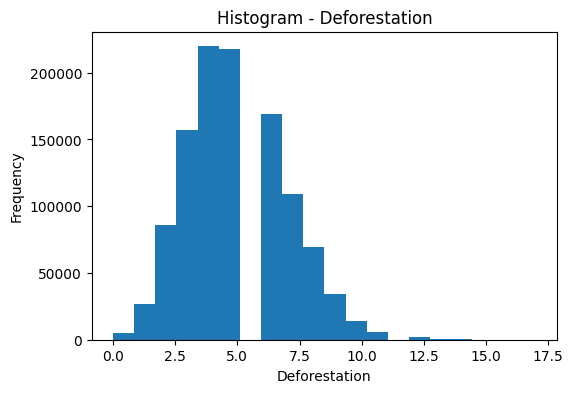

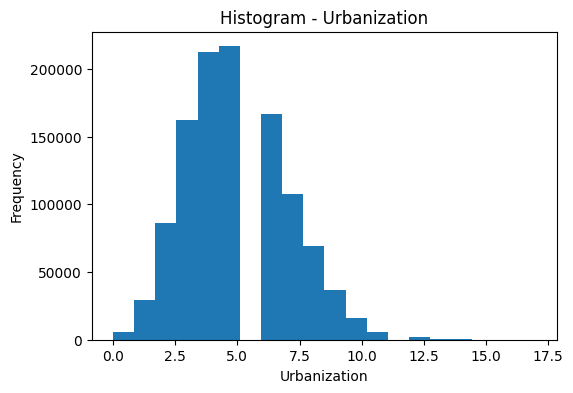

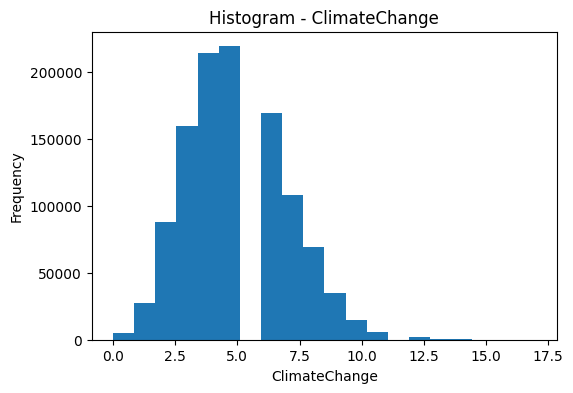

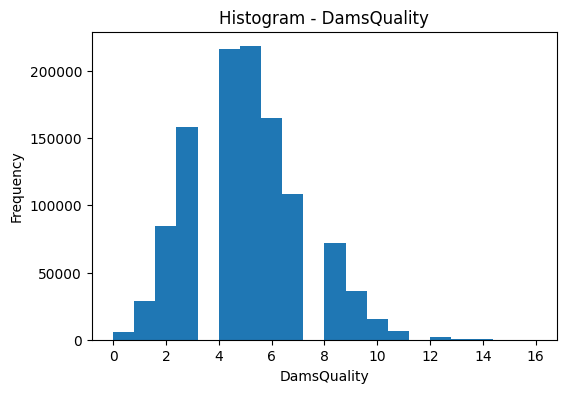

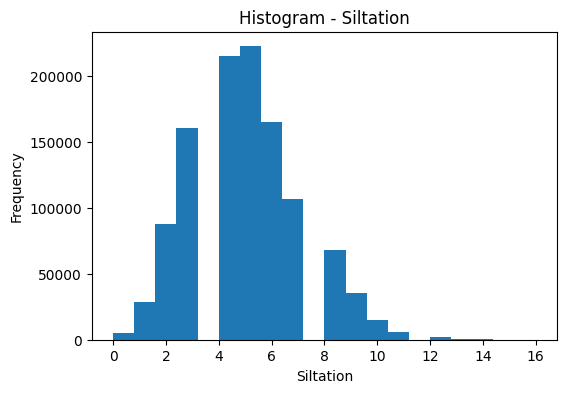

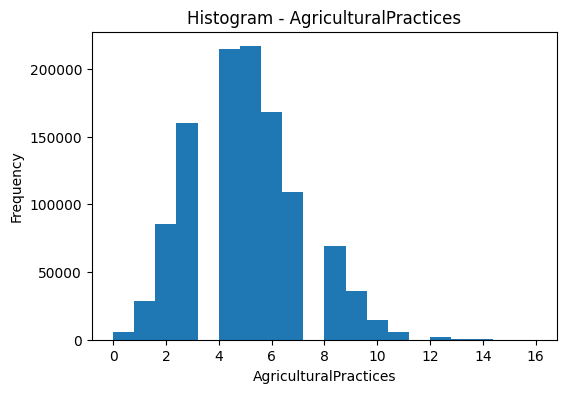

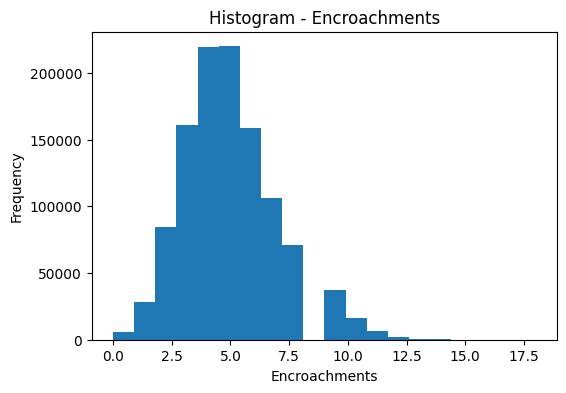

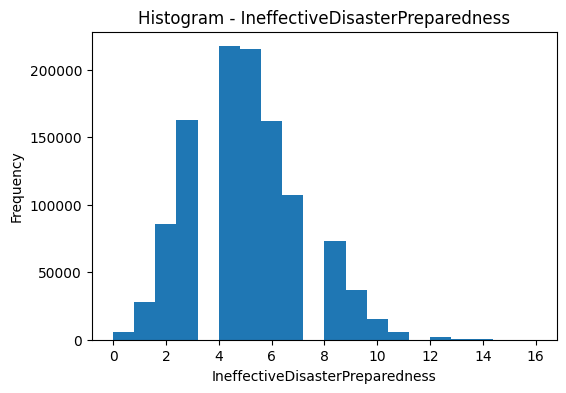

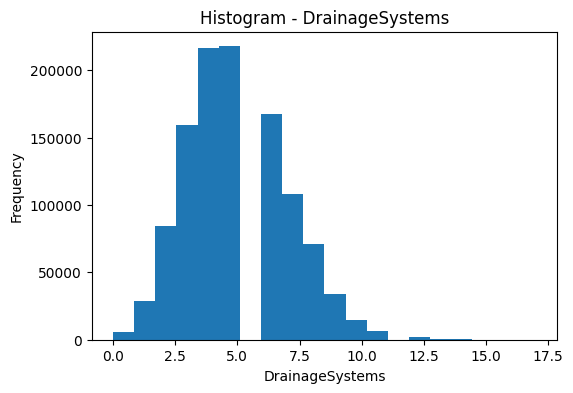

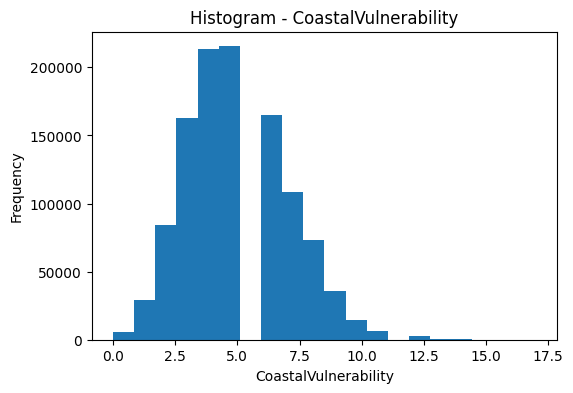

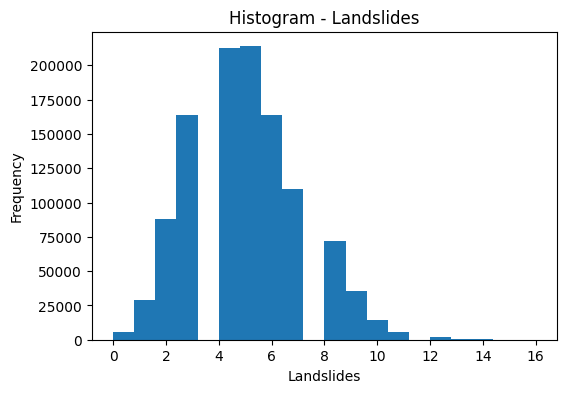

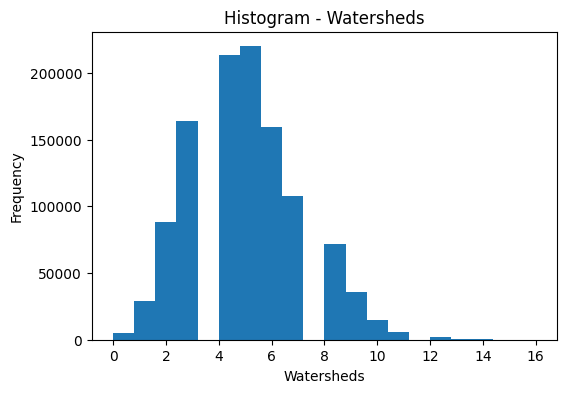

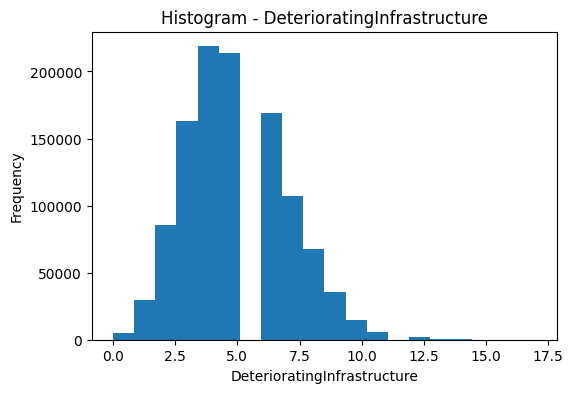

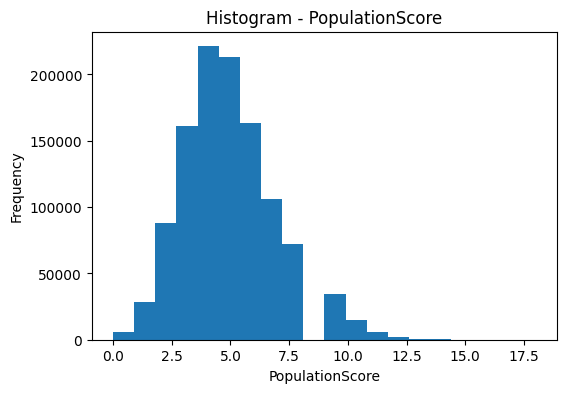

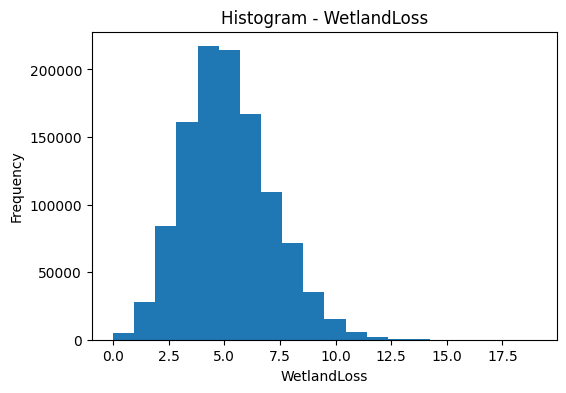

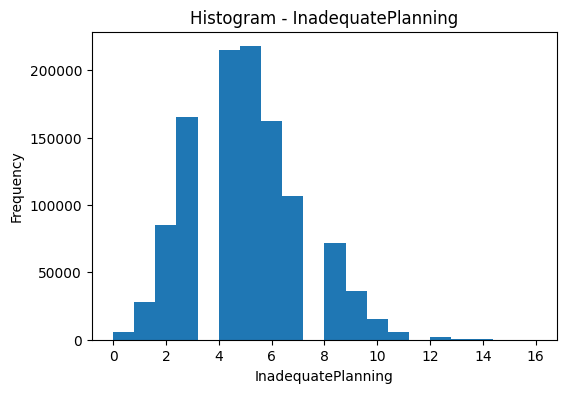

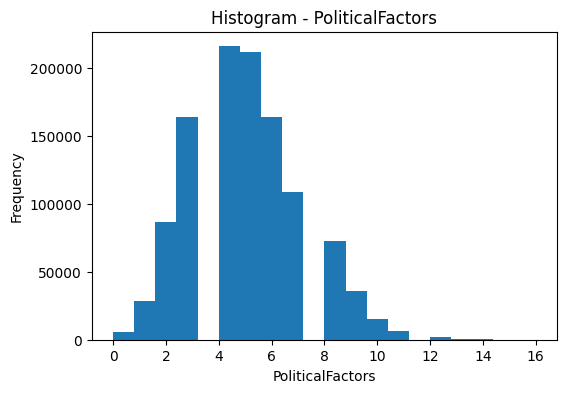

In [6]:
import matplotlib.pyplot as plt

for col in df.columns:
    if col != "FloodProbability":
        plt.figure(figsize=(6,4))
        plt.hist(df[col], bins=20)
        plt.title(f"Histogram - {col}")
        plt.xlabel(col)
        plt.ylabel("Frequency")
        plt.show()

## 6. Feature Distributions

Histograms show how each predictor is distributed. They help identify skewed variables, unusual ranges, concentrated values, and whether the dataset follows the expected 0–10 scoring pattern.

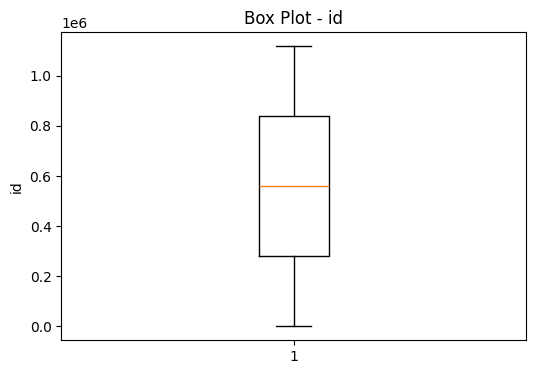

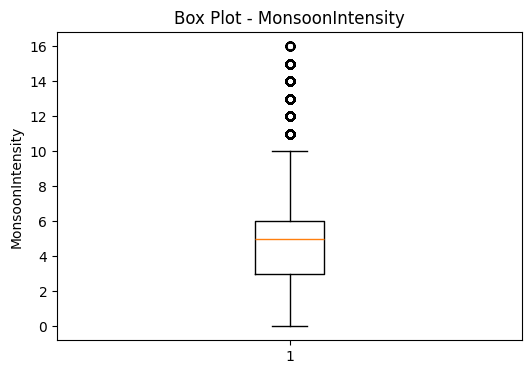

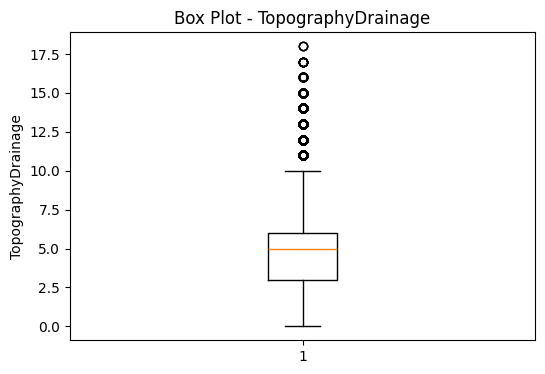

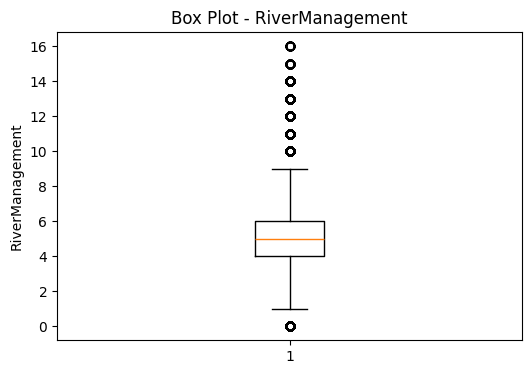

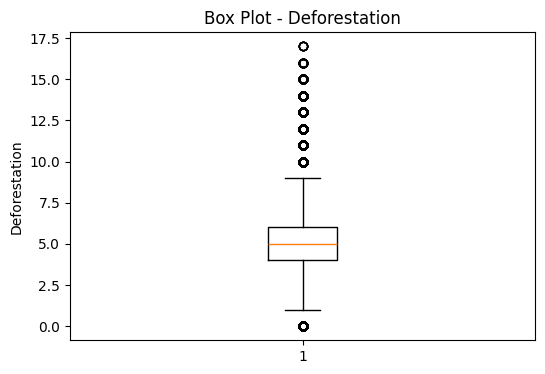

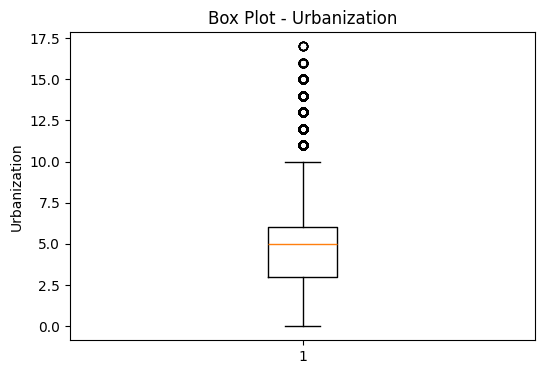

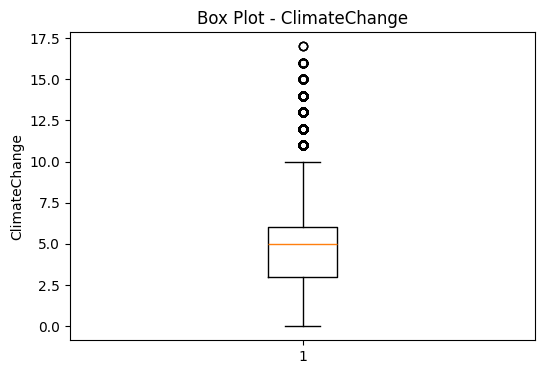

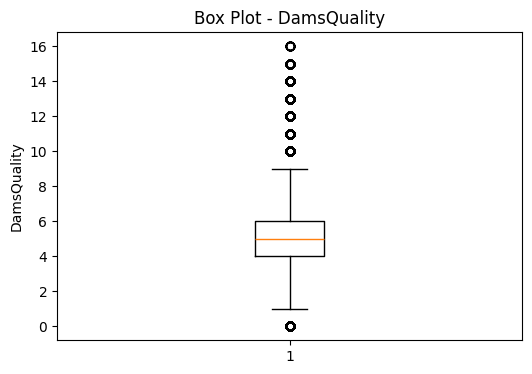

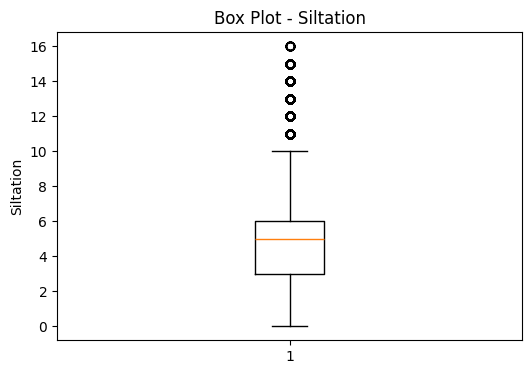

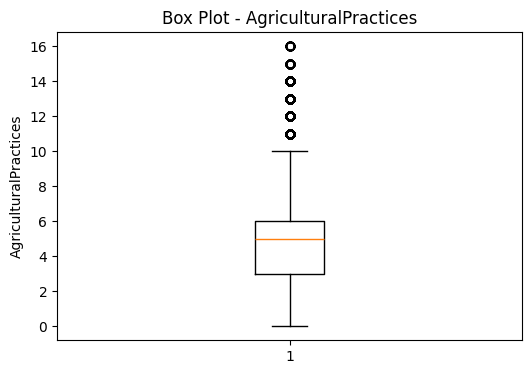

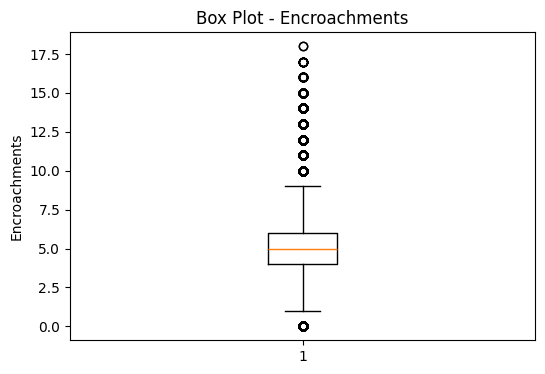

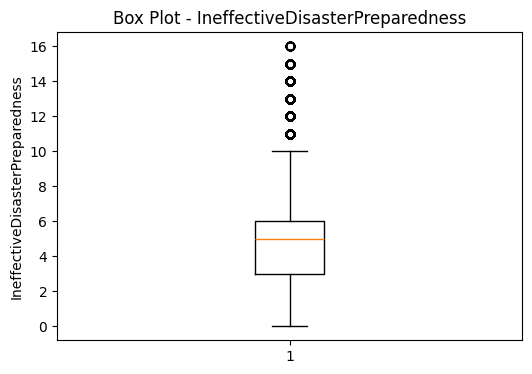

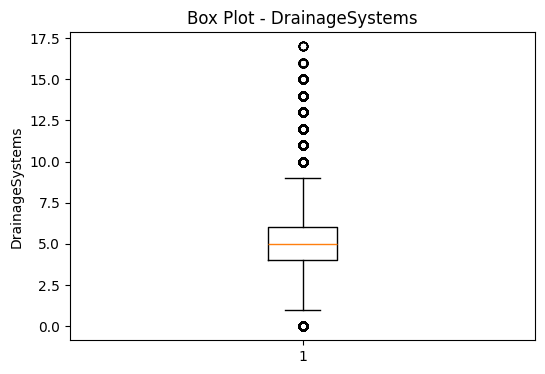

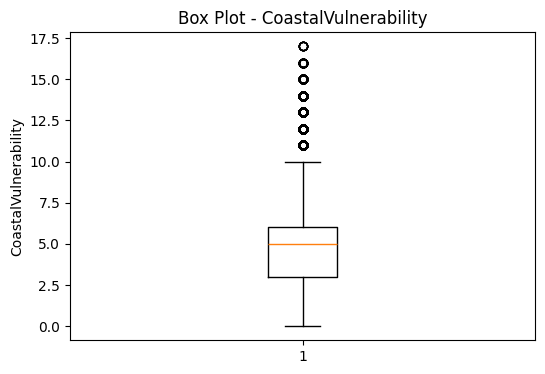

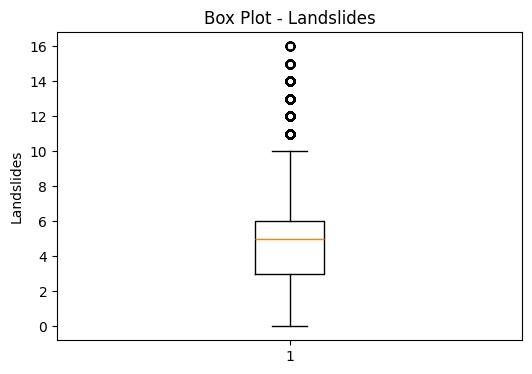

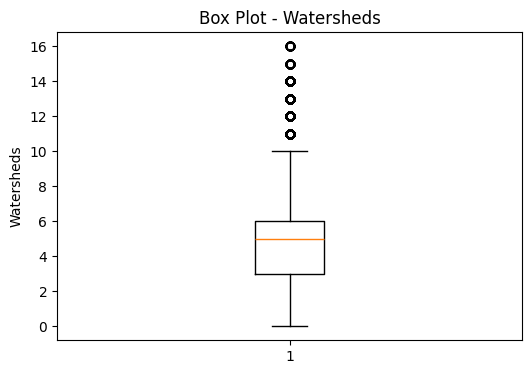

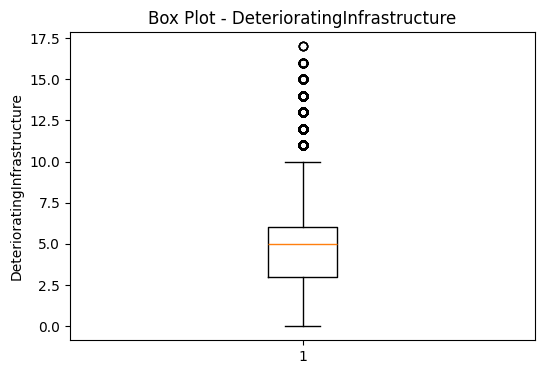

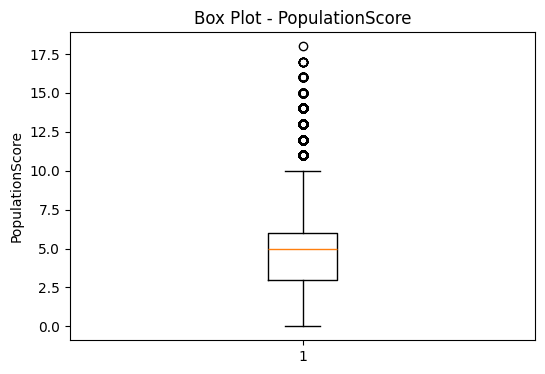

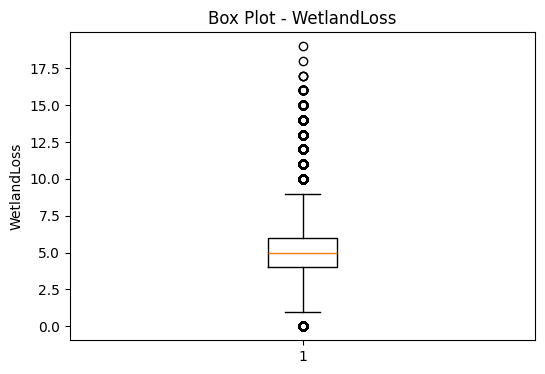

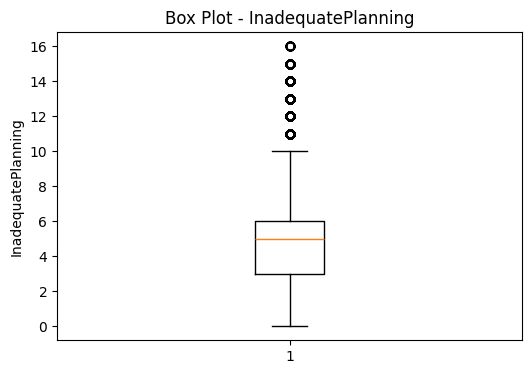

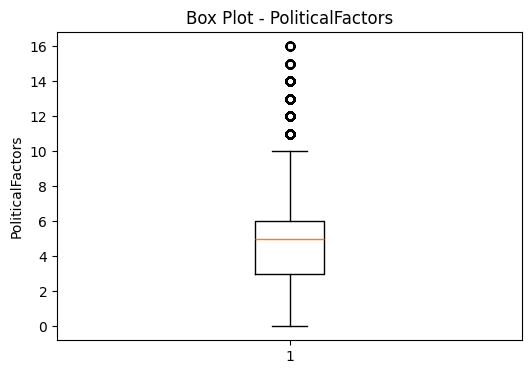

In [7]:
import matplotlib.pyplot as plt

for col in df.columns:
    if col != "FloodProbability":
        plt.figure(figsize=(6,4))
        plt.boxplot(df[col])
        plt.title(f"Box Plot - {col}")
        plt.ylabel(col)
        plt.show()

## 7. Detect Potential Outliers

Box plots provide a compact view of the median, spread, and extreme values for each variable. Potential outliers are investigated before modeling because extreme values can influence a linear regression fit.

In [8]:
import numpy as np

for col in df.select_dtypes(include=['int64', 'float64']).columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = np.where(df[col] < lower, lower, df[col])
    df[col] = np.where(df[col] > upper, upper, df[col])

print("Outliers capped successfully")

Outliers capped successfully


## 8. Cap Outliers Across Numeric Columns

This step applies the interquartile range rule. Values below `Q1 - 1.5 × IQR` or above `Q3 + 1.5 × IQR` are replaced with the corresponding boundary. Capping limits the influence of extreme observations while keeping the rows in the dataset.

In [9]:
for col in df.select_dtypes(include=['int64', 'float64']).columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col, ":", len(outliers))

id : 0
MonsoonIntensity : 0
TopographyDrainage : 0
RiverManagement : 0
Deforestation : 0
Urbanization : 0
ClimateChange : 0
DamsQuality : 0
Siltation : 0
AgriculturalPractices : 0
Encroachments : 0
IneffectiveDisasterPreparedness : 0
DrainageSystems : 0
CoastalVulnerability : 0
Landslides : 0
Watersheds : 0
DeterioratingInfrastructure : 0
PopulationScore : 0
WetlandLoss : 0
InadequatePlanning : 0
PoliticalFactors : 0
FloodProbability : 0


## 9. Verify Remaining Outliers

This diagnostic counts observations outside the IQR boundaries for each column. It helps compare the data before and after capping and confirms whether extreme values remain.

In [10]:
feature_cols = df.drop("FloodProbability", axis=1).columns

for col in feature_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = np.where(df[col] < lower, lower, df[col])
    df[col] = np.where(df[col] > upper, upper, df[col])

print("Feature outliers capped")

Feature outliers capped


## 10. Cap Feature Outliers Only

The target should not be modified based on feature outlier rules. This step therefore applies IQR capping only to the predictor columns, preserving the original meaning of `FloodProbability`.

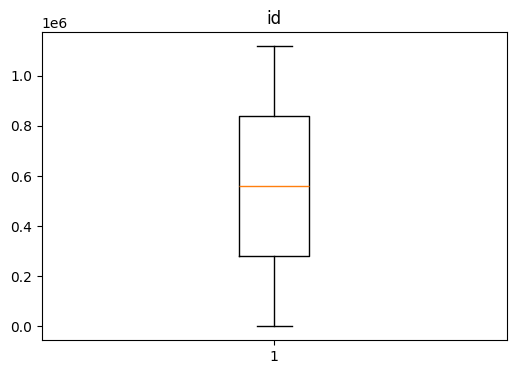

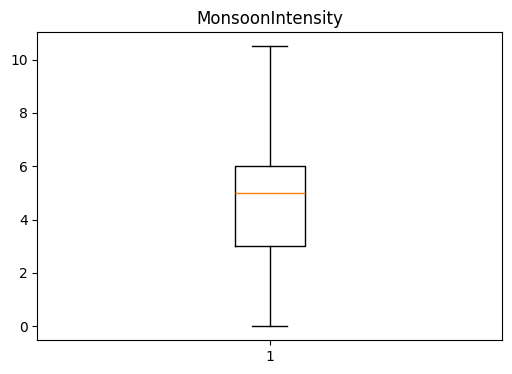

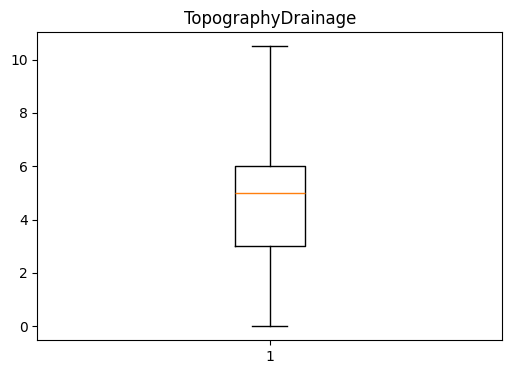

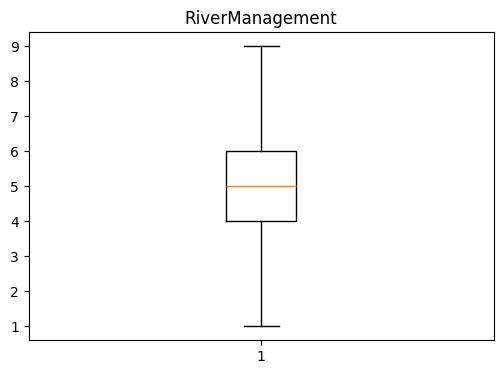

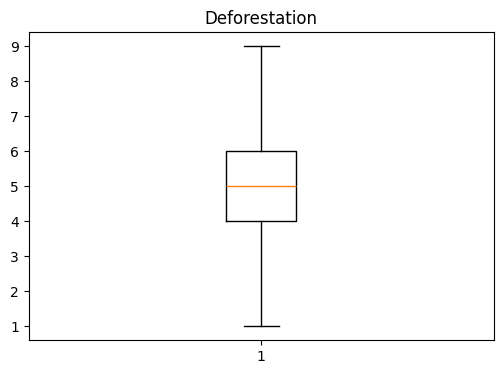

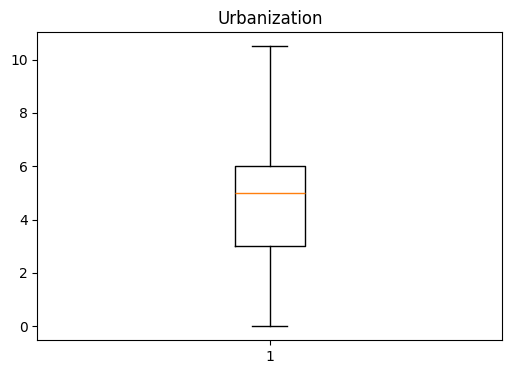

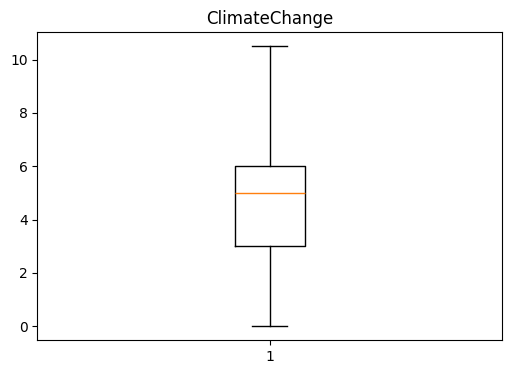

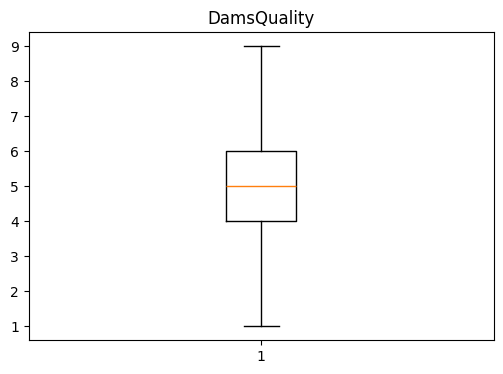

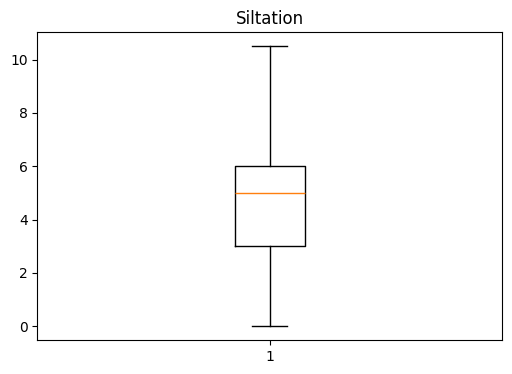

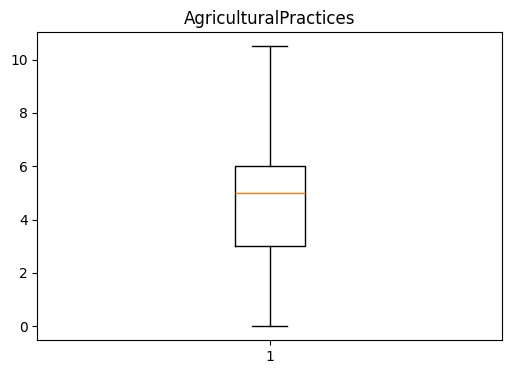

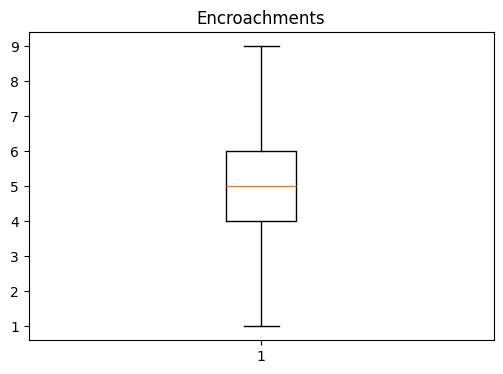

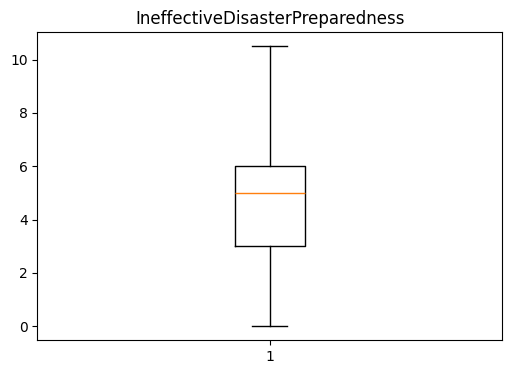

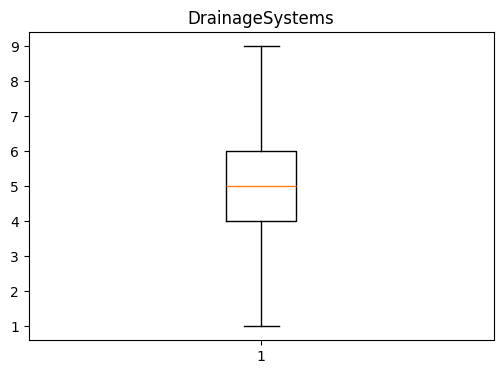

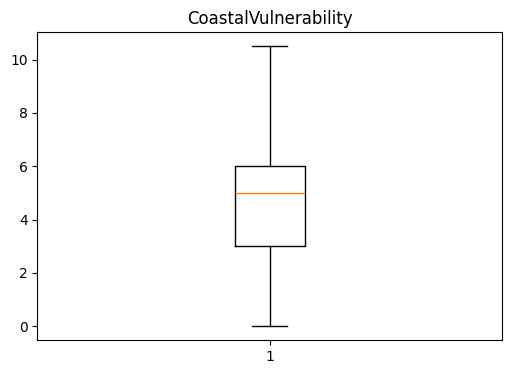

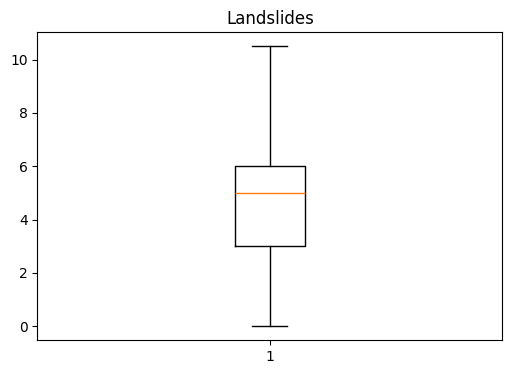

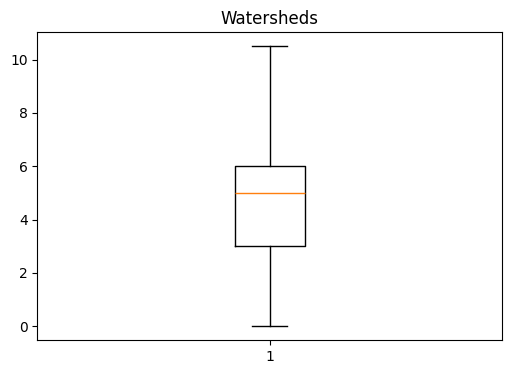

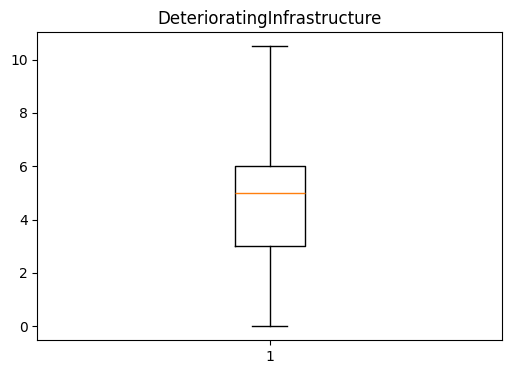

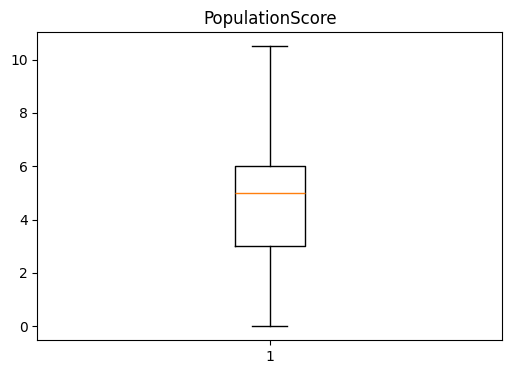

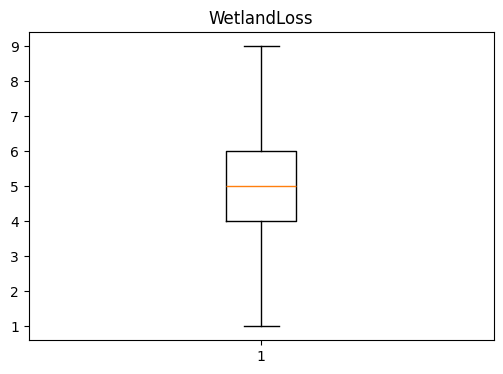

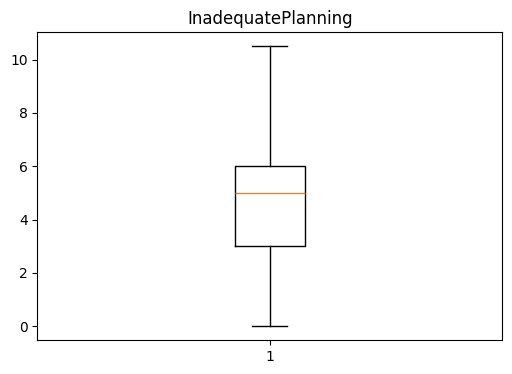

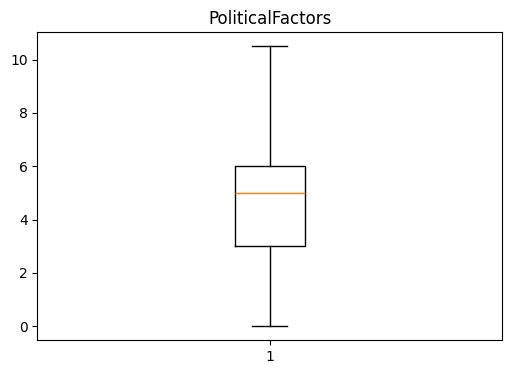

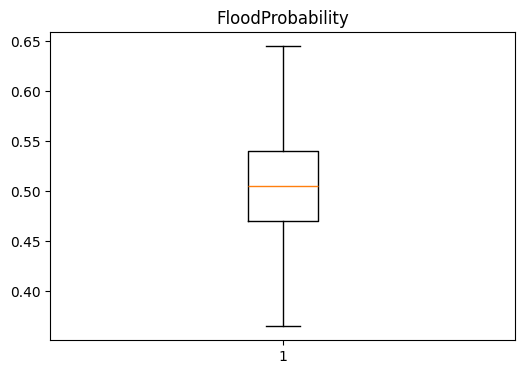

In [11]:
import matplotlib.pyplot as plt

for col in df.select_dtypes(include=['int64','float64']).columns:
    plt.figure(figsize=(6,4))
    plt.boxplot(df[col].dropna())
    plt.title(col)
    plt.show()

## 11. Visualize Cleaned Features

The second set of box plots checks the effect of outlier treatment. Comparing these plots with the earlier plots provides a visual quality-control step before model training.

In [12]:
df = df.drop("id", axis=1)

## 12. Remove the Identifier Column

An identifier is a label for a row, not a meaningful environmental predictor. Removing it prevents the model from learning accidental relationships tied to row identity.

In [13]:
df

,MonsoonIntensity,TopographyDrainage,RiverManagement,Deforestation,Urbanization,ClimateChange,DamsQuality,Siltation,AgriculturalPractices,Encroachments,...,DrainageSystems,CoastalVulnerability,Landslides,Watersheds,DeterioratingInfrastructure,PopulationScore,WetlandLoss,InadequatePlanning,PoliticalFactors,FloodProbability
0,5.0,8.0,5.0,8.0,6.0,4.0,4.0,3.0,3.0,4.0,...,5.0,3.0,3.0,5.0,4.0,7.0,5.0,7.0,3.0,0.445
1,6.0,7.0,4.0,4.0,8.0,8.0,3.0,5.0,4.0,6.0,...,7.0,2.0,0.0,3.0,5.0,3.0,3.0,4.0,3.0,0.450
2,6.0,5.0,6.0,7.0,3.0,7.0,1.0,5.0,4.0,5.0,...,7.0,3.0,7.0,5.0,6.0,8.0,2.0,3.0,3.0,0.530
3,3.0,4.0,6.0,5.0,4.0,8.0,4.0,7.0,6.0,8.0,...,2.0,4.0,7.0,4.0,4.0,6.0,5.0,7.0,5.0,0.535
4,5.0,3.0,2.0,6.0,4.0,4.0,3.0,3.0,3.0,3.0,...,2.0,2.0,6.0,6.0,4.0,1.0,2.0,3.0,5.0,0.415
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1117952,3.0,3.0,4.0,9.0,4.0,5.0,5.0,7.0,10.0,4.0,...,7.0,8.0,7.0,2.0,2.0,1.0,4.0,6.0,4.0,0.495
1117953,2.0,2.0,4.0,3.0,9.0,5.0,8.0,1.0,3.0,5.0,...,9.0,4.0,4.0,3.0,7.0,4.0,9.0,4.0,5.0,0.480
1117954,7.0,3.0,9.0,4.0,6.0,5.0,9.0,1.0,3.0,4.0,...,5.0,5.0,5.0,5.0,6.0,5.0,5.0,2.0,4.0,0.485
1117955,7.0,3.0,3.0,7.0,5.0,2.0,3.0,4.0,6.0,4.0,...,6.0,8.0,5.0,3.0,4.0,6.0,7.0,6.0,4.0,0.495


## 13. Confirm the Modeling Table

This final table preview confirms that the identifier is gone, the target is present, and the cleaned feature set is ready for splitting into training and test data.

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np



X = df.drop("FloodProbability", axis=1)
y = df["FloodProbability"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE :", rmse)
print("R2 Score :", r2)

MAE : 0.016241836863934014
MSE : 0.0004203136614312607
RMSE : 0.020501552659036845
R2 Score : 0.83656447360944


## 14. Train and Evaluate the Regression Model

The data is divided into training and test sets so performance can be measured on unseen observations. A `LinearRegression` model is fitted using the 20 predictors, then evaluated with MAE, MSE, RMSE, and R².

- **MAE** measures the average absolute prediction error.
- **MSE** penalizes larger errors more strongly.
- **RMSE** expresses error in the target's original units.
- **R²** measures how much target variation is explained by the model.

In [16]:
import joblib

joblib.dump(model, "flood_model.joblib")

print("Model Saved Successfully")

Model Saved Successfully


## 15. Save the Trained Model

The fitted model is serialized with `joblib`. Saving the model allows the Streamlit application to make predictions later without retraining on every launch.

In [17]:
import joblib

model = joblib.load("flood_model.joblib")

print("Model Loaded Successfully")

Model Loaded Successfully


## 16. Load the Saved Model

Reloading the artifact verifies that the saved model can be restored successfully. This is the same loading pattern used by the prediction app.

In [18]:
new_data = [[
    5, 6, 4, 3, 7,
    5, 6, 4, 5, 3,
    4, 5, 6, 3, 4,
    5, 7, 4, 3, 2
]]

prediction = model.predict(new_data)

print("Flood Probability :", prediction[0])

Flood Probability : 0.46159442859571054


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


## 17. Generate a New Flood Probability Prediction

A sample observation is supplied in the exact order of the 20 training features. The loaded regression model returns a continuous flood probability estimate, demonstrating the final inference workflow.

## 18. Case Study Conclusion

The project now has a complete machine-learning workflow: inspect the flood dataset, clean numeric inputs, explore relationships, train and evaluate a regression model, save the artifact, and use it for new predictions. The saved model is connected to the Streamlit interface for interactive use.